# Sparse Frames from an Event-Driven Detector

> Georgios Varnavides | Sep 5 2026  
>
> Sample: apoferritin PDB dataset  
> Sampling conditions: 10 A step-size  
> Imaging conditions: 300 kV, 4 mrad, 1.5 um defocus  

A direct electron detector run in event mode does not produce frames. It produces a list of
detected electrons, each with a detector coordinate and a time of arrival. Histogramming that
list into a `(scan_y, scan_x, dp_y, dp_x)` array is the usual first step, and at low dose most
of the array it produces is zero.

`DirectPtychographyMontage.from_vector` skips the histogram and accumulates the electrons
directly. This notebook covers the data format, what the reconstruction does with it, and when
it is worth doing. The reconstructions themselves are the same operator as the dense path, so
the comparison throughout is against `from_dataset3d` on the same counts.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import quantem as em

from quantem.core.datastructures import Dataset3d, Vector

# noisy reconstructions compress poorly, so keep the inline figures modest
plt.rcParams["figure.dpi"] = 72

/Users/gvarnavides/Documents/git-repos/quantem-upstream/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dataset = em.core.io.load("../../data/apoF_4mrad_1.5um-df_10A-step.zip")
dataset = em.core.datastructures.Dataset4dstem.from_array(
    dataset.array[:48, :48],
    sampling=dataset.sampling,
    units=dataset.units,
)
dataset

Dataset(shape=(48, 48, 128, 128), dtype=float32, name='4D-STEM dataset')
  sampling: [10.66666667 10.66666667  0.15380851  0.15380851]
  units: ['A', 'A', 'mrad', 'mrad']
  signal units: 'arb. units'

In [3]:
energy = 300e3
semiangle_cutoff = 4
defocus = 1.5e4
rotation_angle_deg = -15

step = float(dataset.sampling[0])
num_rows, num_cols = dataset.shape[:2]
num_positions = num_rows * num_cols

# The scan step is coarse, so every reconstruction below is sampled on a refined canvas. This
# matters twice over: it is needed for the reconstruction to resolve anything, and it is one of
# the two things that decide whether the event path is faster.
upsampling = 4

# The SSB kernel is not compact in real space, so a stencil of this radius is an approximation.
# Its error grows as the canvas is refined, since the kernel then spans more pixels; radius 8 on
# the 192x192 canvas below is coarse, and is used to keep the notebook quick rather than because
# it is a radius worth keeping.
stencil_radius = 8

# The patterns are simulated about the detector centre, so the diffraction origin is known
# rather than something to fit. Pinning it keeps every model below on identical data; section 3
# covers what happens when it is fitted instead and lands off the pixel grid.
origin = (dataset.shape[-2] // 2, dataset.shape[-1] // 2)

kwargs = dict(
    energy=energy,
    semiangle_cutoff=semiangle_cutoff,
    rotation_angle=rotation_angle_deg,
    aberration_coefs={"defocus": defocus},
    scan_sampling=(step, step),
    force_fitted_origin=origin,
    boundary="wrap",
    verbose=False,
)

print(f"{num_rows} x {num_cols} scan positions, {step:.2f} A step")
print(f"{dataset.shape[-2]} x {dataset.shape[-1]} detector, {dataset.sampling[-1]:.4f} {dataset.units[-1]}/px")

48 x 48 scan positions, 10.67 A step
128 x 128 detector, 0.1538 mrad/px


The dataset ships at infinite dose, with each pattern normalised to unit total intensity, so a
counted acquisition is a Poisson draw from it. The electrons landing on one pattern are the dose
per unit area times the area one probe position covers.

In [4]:
def counted(dataset, electrons_per_area, rng):
    """Poisson counts at a given fluence, as an integer array."""
    electrons_per_probe = electrons_per_area * dataset.sampling[:2].prod()
    return rng.poisson(np.asarray(dataset.array) * electrons_per_probe)


rng = np.random.default_rng(0)
counts = counted(dataset, 10.0, rng)

print(f"{counts.sum():,} electrons over {num_positions:,} patterns")
print(f"{counts.mean() * 100:.2f}% of the array is nonzero on average")

2,620,655 electrons over 2,304 patterns
6.94% of the array is nonzero on average


## How empty the frames are

What matters for the reconstruction is not the whole detector but the bright-field disk, since
that is what the kernels are summed over. The useful figure is the occupancy of the
`(bright-field pixel, scan position)` grid: the fraction of those cells that caught at least one
electron.

In [5]:
mean_pattern = np.asarray(dataset.dp_mean.array)
bf_mask = mean_pattern > mean_pattern.max() * 0.5
num_bf = int(bf_mask.sum())

print(f"{num_bf} bright-field pixels of {mean_pattern.size} on the detector")
print()
print(f"{'dose (e/A^2)':>13} {'e / pattern':>12} {'e / BF px':>10} {'occupancy':>10}")
for dose in (10.0, 50.0, 100.0):
    frames = counted(dataset, dose, np.random.default_rng(1))
    occupied = (frames[..., bf_mask] > 0).mean()
    per_pattern = dose * dataset.sampling[:2].prod()
    print(f"{dose:>13.0f} {per_pattern:>12.0f} {per_pattern / num_bf:>10.2f} {occupied:>9.1%}")

2114 bright-field pixels of 16384 on the detector

 dose (e/A^2)  e / pattern  e / BF px  occupancy
           10         1138       0.54     41.2%
           50         5689       2.69     92.8%
          100        11378       5.38     99.4%


A 10 Ang step puts a lot of dose behind each pattern, so the frames are only really empty at the
low end. A finer step spreads the same fluence over more patterns and empties them further, which
is why occupancy rather than dose is the number to reason about.

The mask above is centred on the detector, the way the raw patterns are. The reconstruction
works on an origin-shifted stack whose disk sits at the corner, so anything passed as `bf_mask`
has to be rolled into that frame. Leaving `bf_mask` out lets each constructor threshold the mean
pattern itself, which is fine as long as every model being compared sees the same data.

In [6]:
corner_centered_bf_mask = np.roll(bf_mask, (-origin[0], -origin[1]), axis=(0, 1))

## From an event stream to a `Vector`

A TimePix-style stream is a flat list of `(x, y, t)`, one row per detected electron, ordered by
time of arrival. There are no frame boundaries in it. Below is such a stream synthesised from the
counted array, with each electron given a random arrival within its position's dwell.

In [7]:
dwell = 10e-6  # seconds per scan position

flat_counts = counts.reshape(num_positions, *counts.shape[-2:])
position_index, kx, ky = np.nonzero(flat_counts)
repeats = flat_counts[position_index, kx, ky]
position_index, kx, ky = (np.repeat(a, repeats) for a in (position_index, kx, ky))

time_of_arrival = (position_index + rng.random(position_index.size)) * dwell
order = np.argsort(time_of_arrival)
stream = np.stack([kx[order], ky[order], time_of_arrival[order]], axis=-1)

print(f"stream of {len(stream):,} events, columns (x, y, ToA)")
print(stream[:4])

stream of 2,620,655 events, columns (x, y, ToA)
[[8.20000000e+01 6.50000000e+01 8.01348155e-10]
 [5.00000000e+01 7.90000000e+01 2.11677581e-08]
 [6.20000000e+01 4.00000000e+01 5.58375618e-08]
 [4.40000000e+01 6.30000000e+01 7.40693699e-08]]


The time column is what assigns each electron to a scan position, rather than something to sum
over. Dividing the arrival time by the dwell recovers the position index, which for a real
acquisition means folding in the trigger and the flyback rather than a bare division.

Once each electron carries a position index, the remaining structure is a ragged one: every
position holds a different number of electrons. That is what `Vector` stores, with the fixed grid
being the scan and the ragged rows being the detections.

In [8]:
x, y, t = stream[:, 0].astype(int), stream[:, 1].astype(int), stream[:, 2]
frame = np.floor(t / dwell).astype(int)

# group the stream by position, then by detector pixel within a position
order = np.lexsort((y, x, frame))
frame, x, y = frame[order], x[order], y[order]
bounds = np.searchsorted(frame, np.arange(num_positions + 1))

per_electron = [
    np.stack([x[lo:hi], y[lo:hi]], axis=-1).astype(float) for lo, hi in zip(bounds[:-1], bounds[1:])
]
grid = [per_electron[i * num_cols : (i + 1) * num_cols] for i in range(num_rows)]

events = Vector.from_data(grid, fields=["kx", "ky"], units=["px", "px"], name="events")
events

quantem.Vector, shape=(48, 48), name=events
  fields = ['kx', 'ky']
  units: ['px', 'px']

A pixel struck more than once inside one dwell appears as repeated rows. Collapsing those repeats
into a count is worth doing, and it is what the third field in the `Vector` docstring's
`("kx", "ky", "intensity")` example is for.

In [9]:
aggregated = []
for lo, hi in zip(bounds[:-1], bounds[1:]):
    pixels = np.stack([x[lo:hi], y[lo:hi]], axis=-1)
    unique, repeats = np.unique(pixels, axis=0, return_counts=True)
    aggregated.append(np.concatenate([unique, repeats[:, None]], axis=-1).astype(float))

grid = [aggregated[i * num_cols : (i + 1) * num_cols] for i in range(num_rows)]
events_weighted = Vector.from_data(
    grid, fields=["kx", "ky", "intensity"], units=["px", "px", "counts"], name="events"
)

print(f"one row per electron : {events.total_rows:,}")
print(f"one row per pixel hit: {events_weighted.total_rows:,}"
      f"  ({events_weighted.total_rows / events.total_rows:.0%} as many)")

one row per electron : 2,620,655
one row per pixel hit: 2,035,140  (78% as many)


The two forms reconstruct identically. `from_vector` sums rows that share a
`(detector pixel, scan position)` cell whichever form it is given, so a stored weight is always
that cell's intensity rather than one electron's contribution to it. That matters beyond
tidiness: `residual_loss` accumulates the square of the value, and two electrons in a pixel are
not the same as one electron of twice the weight.

Aggregating up front therefore changes the memory the `Vector` occupies, not the result. Pass
`weight_field="intensity"` to use the third column.

When you already hold counted frames rather than a stream, `vector_from_frames` does the same
conversion in one call.

In [10]:
from_frames = em.diffractive_imaging.vector_from_frames(counts)
from_frames_weighted = em.diffractive_imaging.vector_from_frames(
    counts, fields=("kx", "ky", "intensity")
)

print(f"vector_from_frames rows        : {from_frames.total_rows:,}")
print(f"vector_from_frames, aggregated : {from_frames_weighted.total_rows:,}")
print(f"matches the decoded stream     : {from_frames.total_rows == events.total_rows}")

vector_from_frames rows        : 2,620,655
vector_from_frames, aggregated : 2,035,140
matches the decoded stream     : True


## Reconstructing from events

`from_vector` needs two things a `Vector` does not carry: where the probe was, and how the
detector is calibrated. Both come off the dataset. `probe_positions` builds the `(N, 2)` scan
positions from the dataset's `origin` and `sampling`, ordered row-major to match a `Vector` whose
fixed grid is the scan. Any 2D dataset in detector space, `dp_mean` being the obvious one, states
the detector shape, sampling and units together.

Stating the detector as a triple of numbers instead is possible, and easy to get wrong. This
dataset is calibrated in `mrad`, and passing that number where `A^-1` was expected would rescale
every spatial frequency without raising anything.

In [11]:
positions = dataset.probe_positions()
print(positions)
print(f"first three: {positions.array[:3].tolist()}")

quantem Dataset named '4D-STEM dataset probe positions'
  shape: (2304, 2)
  dtype: float64
  device: cpu
  origin: [0. 0.]
  sampling: [1. 1.]
  units: ['A', 'A']
  signal units: 'A'
first three: [[0.0, 0.0], [0.0, 10.666666666666666], [0.0, 21.333333333333332]]


In [12]:
sparse = em.diffractive_imaging.DirectPtychographyMontage.from_vector(
    events,
    positions,
    dataset.dp_mean,
    bf_mask=corner_centered_bf_mask,
    **kwargs,
)

dense_stack = Dataset3d.from_array(
    counts.reshape(num_positions, *counts.shape[-2:]).astype(np.float32),
    name="counted frames",
    units=("index", *dataset.units[-2:]),
    sampling=(1, *dataset.sampling[-2:]),
)
dense = em.diffractive_imaging.DirectPtychographyMontage.from_dataset3d(
    dense_stack,
    positions,
    bf_mask=corner_centered_bf_mask,
    **kwargs,
)

cells = sparse.num_bf * sparse.num_positions
print(f"{sparse.num_bf} bright-field pixels, {sparse.num_positions} positions")
print(f"dense stack : {cells:,} values")
print(f"event table : {sparse.events.weights.numel():,} rows"
      f" ({sparse.events.weights.numel() / cells:.1%} occupancy)")

2114 bright-field pixels, 2304 positions
dense stack : 4,870,656 values
event table : 2,004,772 rows (41.2% occupancy)


Both constructors remove the diffraction origin before anything else. Here it is pinned to the
detector centre, so nothing is shifted and the two paths see identical data. On an experimental
dataset the origin is fitted instead, and it generally lands off the pixel grid.

The dense path resamples each pattern to shift it, which spreads intensity over neighbouring
detector pixels. `from_vector` rounds the correction onto the grid instead, since a detection is
a discrete event and splitting it fractionally would invent counts that were never measured and
correlate the shot noise of adjacent pixels. It also keeps the list as sparse as the counts are.
`mode="bilinear"` is available for when the point is to reproduce `from_dataset3d` exactly, at
roughly twice the rows.

In [13]:
fitted = dict(kwargs)
del fitted["force_fitted_origin"]  # fit the origin instead of pinning it

for mode in ("nearest", "bilinear"):
    model = em.diffractive_imaging.DirectPtychographyMontage.from_vector(
        events, positions, dataset.dp_mean, mode=mode,
        bf_mask=corner_centered_bf_mask, **fitted,
    )
    rows = model.events.weights.numel()
    print(f"mode={mode:<9} {rows:>9,} rows, {rows / cells:>5.1%} occupancy")

mode=nearest   2,004,772 rows, 41.2% occupancy
mode=bilinear  4,244,860 rows, 87.2% occupancy


The deconvolution kernels are not compact in real space, so the event path evaluates them as a
truncated stencil rather than by FFT. Both models below are given the same radius, which makes the
comparison one of algorithm rather than of approximation.

In [14]:
ssb = dict(
    deconvolution_kernel="ssb",
    convolution_mode="stencil",
    stencil_radius=stencil_radius,
    upsampling_factor=upsampling,
    verbose=False,
)


def correlation(a, b):
    a, b = np.asarray(a, float).ravel(), np.asarray(b, float).ravel()
    a, b = a - a.mean(), b - b.mean()
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum()))


obj_dense = np.asarray(dense.reconstruct(**ssb).obj)
obj_sparse = np.asarray(sparse.reconstruct(**ssb).obj)

print(f"canvas {obj_dense.shape}")
print(f"relative difference: {np.abs(obj_sparse - obj_dense).max() / np.abs(obj_dense).max():.2e}")

/var/folders/4k/wtzmrt4x0sq19vz44dn3cwzwkblbyl/T/ipykernel_89652/3788737701.py:16: UserWarning: A stencil radius of 8 px leaves an estimated 91% truncation error (worst bright-field pixel 93%). The SSB kernel is not compact in real space -- dividing by |gamma| leaves a phase on a hard-edged support, whose transform has tails decaying as r**-1.5, so the error falls only like 1/radius and being in focus does not help. DirectPtychography computes the same kernel exactly by FFT; prefer it unless the scan is ungridded. This estimate assumes a white object spectrum, so it is pessimistic for a real one.
  obj_dense = np.asarray(dense.reconstruct(**ssb).obj)
/var/folders/4k/wtzmrt4x0sq19vz44dn3cwzwkblbyl/T/ipykernel_89652/3788737701.py:17: UserWarning: A stencil radius of 8 px leaves an estimated 91% truncation error (worst bright-field pixel 93%). The SSB kernel is not compact in real space -- dividing by |gamma| leaves a phase on a hard-edged support, whose transform has tails decaying as r*

canvas (192, 192)
relative difference: 2.45e-05


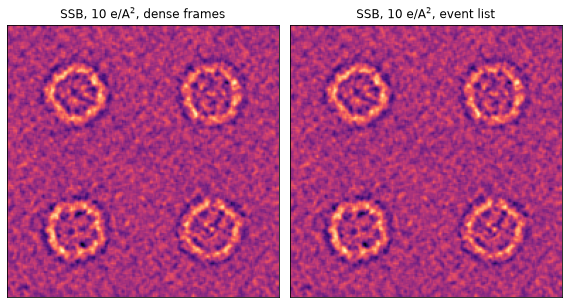

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4.2))
for ax, image, title in zip(axes, (obj_dense, obj_sparse), ("dense frames", "event list")):
    ax.imshow(image, cmap="magma")
    ax.set_title(f"SSB, 10 e/A$^2$, {title}")
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()

## Which kernels use the sparsity

Not every kernel benefits, and it is worth being explicit about which does what.

`ssb` and `obf` are the case sparsity is for. Each deposits a truncated kernel once per
occupied cell, so the work follows the electrons. The Fourier route is refused for these, because
it transforms one canvas per bright-field pixel at a cost set by the canvas rather than by the
counts, which would amount to histogramming the events back into frames.

`icom` reads only the per-position centre of mass, which is one weighted sum over that position's
rows. The riCOM collapse is exact and cheap at any occupancy, so it keeps both convolution modes.

`prlx` gains memory and nothing else. Its deposit lands at every `(bright-field pixel, position)`
pair whatever the value, so the weight map and the scan mean it subtracts stay dense however few
electrons arrived.

In [16]:
try:
    sparse.reconstruct(deconvolution_kernel="ssb", convolution_mode="fft", verbose=False)
except ValueError as exc:
    print(exc)

`convolution_mode='fft'` is unavailable for the 'ssb' kernel on sparse frames: it transforms one canvas per bright-field pixel at a cost independent of the counts, so it would histogram the events back into dense frames. Use `convolution_mode='stencil'`, or build the montage with `from_dataset3d` if you want the exact, untruncated kernel.


In [17]:
print(f"{'kernel':<14} {'relative difference':>20}")
for kernel, extra in (
    ("prlx", dict(parallax_flip_phase=False)),
    ("icom", dict(convolution_mode="fft")),
    ("icom", dict(convolution_mode="stencil", stencil_radius=stencil_radius)),
):
    settings = dict(
        deconvolution_kernel=kernel, upsampling_factor=upsampling, verbose=False, **extra
    )
    a = np.asarray(dense.reconstruct(**settings).obj)
    b = np.asarray(sparse.reconstruct(**settings).obj)
    label = f"{kernel} {extra.get('convolution_mode', 'splat')}"
    print(f"{label:<14} {np.abs(b - a).max() / np.abs(a).max():>20.2e}")

kernel          relative difference
prlx splat                 1.00e-07
icom fft                   9.04e-08
icom stencil               2.64e-07


## When the event path is faster

The two accumulations scale differently. The dense path runs a grouped convolution that visits
`num_bf * canvas_pixels` regardless of what those pixels hold. The event path visits the detected
electrons, and does not grow with the canvas.

That makes `upsampling_factor` as important as the dose. A wrapped canvas has one pixel per scan
position at `upsampling_factor=1` and sixteen times as many at 4, while the event count is
unchanged. The sweep below holds the stencil radius fixed so the table shows the canvas
dependence on its own.

In [18]:
def timed(model, **settings):
    model.reconstruct(**settings)  # warm up, so the probe resampling is cached for both
    start = time.perf_counter()
    model.reconstruct(**settings)
    return time.perf_counter() - start


print(f"{'upsampling':>10} {'canvas':>12} {'dense':>9} {'events':>9} {'speedup':>9}")
for factor in (1, 2, 4):
    settings = dict(
        deconvolution_kernel="ssb",
        convolution_mode="stencil",
        stencil_radius=stencil_radius,
        upsampling_factor=factor,
        verbose=False,
    )
    t_dense = timed(dense, **settings)
    t_sparse = timed(sparse, **settings)
    canvas = tuple(dense.obj.shape)
    print(f"{factor:>10} {str(canvas):>12} {t_dense:>8.2f}s {t_sparse:>8.2f}s"
          f" {t_dense / t_sparse:>8.2f}x")

upsampling       canvas     dense    events   speedup


/var/folders/4k/wtzmrt4x0sq19vz44dn3cwzwkblbyl/T/ipykernel_89652/1428101608.py:2: UserWarning: A stencil radius of 8 px leaves an estimated 18% truncation error (worst bright-field pixel 24%). The SSB kernel is not compact in real space -- dividing by |gamma| leaves a phase on a hard-edged support, whose transform has tails decaying as r**-1.5, so the error falls only like 1/radius and being in focus does not help. DirectPtychography computes the same kernel exactly by FFT; prefer it unless the scan is ungridded. This estimate assumes a white object spectrum, so it is pessimistic for a real one.
  model.reconstruct(**settings)  # warm up, so the probe resampling is cached for both
/var/folders/4k/wtzmrt4x0sq19vz44dn3cwzwkblbyl/T/ipykernel_89652/1428101608.py:4: UserWarning: A stencil radius of 8 px leaves an estimated 18% truncation error (worst bright-field pixel 24%). The SSB kernel is not compact in real space -- dividing by |gamma| leaves a phase on a hard-edged support, whose tran

         1     (48, 48)     1.86s     2.31s     0.81x


/var/folders/4k/wtzmrt4x0sq19vz44dn3cwzwkblbyl/T/ipykernel_89652/1428101608.py:2: UserWarning: A stencil radius of 8 px leaves an estimated 32% truncation error (worst bright-field pixel 44%). The SSB kernel is not compact in real space -- dividing by |gamma| leaves a phase on a hard-edged support, whose transform has tails decaying as r**-1.5, so the error falls only like 1/radius and being in focus does not help. DirectPtychography computes the same kernel exactly by FFT; prefer it unless the scan is ungridded. This estimate assumes a white object spectrum, so it is pessimistic for a real one.
  model.reconstruct(**settings)  # warm up, so the probe resampling is cached for both
/var/folders/4k/wtzmrt4x0sq19vz44dn3cwzwkblbyl/T/ipykernel_89652/1428101608.py:4: UserWarning: A stencil radius of 8 px leaves an estimated 32% truncation error (worst bright-field pixel 44%). The SSB kernel is not compact in real space -- dividing by |gamma| leaves a phase on a hard-edged support, whose tran

         2     (96, 96)     2.58s     2.63s     0.98x


/var/folders/4k/wtzmrt4x0sq19vz44dn3cwzwkblbyl/T/ipykernel_89652/1428101608.py:2: UserWarning: A stencil radius of 8 px leaves an estimated 91% truncation error (worst bright-field pixel 93%). The SSB kernel is not compact in real space -- dividing by |gamma| leaves a phase on a hard-edged support, whose transform has tails decaying as r**-1.5, so the error falls only like 1/radius and being in focus does not help. DirectPtychography computes the same kernel exactly by FFT; prefer it unless the scan is ungridded. This estimate assumes a white object spectrum, so it is pessimistic for a real one.
  model.reconstruct(**settings)  # warm up, so the probe resampling is cached for both
/var/folders/4k/wtzmrt4x0sq19vz44dn3cwzwkblbyl/T/ipykernel_89652/1428101608.py:4: UserWarning: A stencil radius of 8 px leaves an estimated 91% truncation error (worst bright-field pixel 93%). The SSB kernel is not compact in real space -- dividing by |gamma| leaves a phase on a hard-edged support, whose tran

         4   (192, 192)     6.51s     4.33s     1.50x


Both timings include building the kernel stencil, which is the same work either way and does not
depend on the counts, so the ratios understate the difference in the accumulation itself.

The rule the numbers follow is that the event path wins when the detected electrons number fewer
than about `num_bf * canvas_pixels / 7`, the constant being how much more efficient a blocked
convolution is per element than a scatter-add. Dose and upsampling both enter, so it is worth
looking at them together.

In [19]:
print(f"{'dose':>6} {'occupancy':>10} " + " ".join(f"{'u=' + str(u):>10}" for u in (1, 2, 4)))
for dose in (1.0, 10.0, 100.0):
    frames = counted(dataset, dose, np.random.default_rng(2))
    stack = Dataset3d.from_array(
        frames.reshape(num_positions, *frames.shape[-2:]).astype(np.float32),
        name="counted frames",
        units=("index", *dataset.units[-2:]),
        sampling=(1, *dataset.sampling[-2:]),
    )
    a = em.diffractive_imaging.DirectPtychographyMontage.from_dataset3d(
        stack, positions, bf_mask=corner_centered_bf_mask, **kwargs
    )
    b = em.diffractive_imaging.DirectPtychographyMontage.from_vector(
        em.diffractive_imaging.vector_from_frames(frames), positions, dataset.dp_mean,
        bf_mask=corner_centered_bf_mask, **kwargs,
    )
    row = f"{dose:>6.0f} {b.events.weights.numel() / cells:>9.1%} "
    for factor in (1, 2, 4):
        settings = dict(
            deconvolution_kernel="ssb", convolution_mode="stencil",
            stencil_radius=stencil_radius, upsampling_factor=factor, verbose=False,
        )
        row += f" {timed(a, **settings) / timed(b, **settings):>9.2f}x"
    print(row)

  dose  occupancy        u=1        u=2        u=4


/var/folders/4k/wtzmrt4x0sq19vz44dn3cwzwkblbyl/T/ipykernel_89652/1428101608.py:2: UserWarning: A stencil radius of 8 px leaves an estimated 18% truncation error (worst bright-field pixel 24%). The SSB kernel is not compact in real space -- dividing by |gamma| leaves a phase on a hard-edged support, whose transform has tails decaying as r**-1.5, so the error falls only like 1/radius and being in focus does not help. DirectPtychography computes the same kernel exactly by FFT; prefer it unless the scan is ungridded. This estimate assumes a white object spectrum, so it is pessimistic for a real one.
  model.reconstruct(**settings)  # warm up, so the probe resampling is cached for both
/var/folders/4k/wtzmrt4x0sq19vz44dn3cwzwkblbyl/T/ipykernel_89652/1428101608.py:4: UserWarning: A stencil radius of 8 px leaves an estimated 18% truncation error (worst bright-field pixel 24%). The SSB kernel is not compact in real space -- dividing by |gamma| leaves a phase on a hard-edged support, whose tran

     1      5.2%       1.14x      1.30x      1.79x
    10     41.2%       0.80x      1.02x      1.54x
   100     99.4%       0.48x      0.66x      1.19x


So on this dataset the event path is the slower of the two unupsampled, and the faster one on a
refined canvas, by a margin that grows as the dose falls. A 10 Ang step is a demanding case for
it, since each probe position collects a lot of dose; a finer step at the same fluence moves every
row of that table in its favour.

## Across dose

Correlations below are against the infinite-dose reconstruction of the same kernel, which is the
best that kernel and stencil can do rather than the true object.

In [20]:
doses = (10.0, 50.0, 100.0)
kernels = {
    "prlx": dict(deconvolution_kernel="prlx", parallax_flip_phase=True),
    "ssb": dict(
        deconvolution_kernel="ssb", convolution_mode="stencil", stencil_radius=stencil_radius
    ),
}

reference_model = em.diffractive_imaging.DirectPtychographyMontage.from_dataset3d(
    Dataset3d.from_array(
        np.asarray(dataset.array).reshape(num_positions, *counts.shape[-2:]).astype(np.float32),
        name="infinite dose",
        units=("index", *dataset.units[-2:]),
        sampling=(1, *dataset.sampling[-2:]),
    ),
    positions,
    bf_mask=corner_centered_bf_mask,
    **kwargs,
)
reference = {
    name: np.asarray(
        reference_model.reconstruct(
            upsampling_factor=upsampling, verbose=False, **settings
        ).obj
    )
    for name, settings in kernels.items()
}

/var/folders/4k/wtzmrt4x0sq19vz44dn3cwzwkblbyl/T/ipykernel_89652/2063357318.py:22: UserWarning: A stencil radius of 8 px leaves an estimated 91% truncation error (worst bright-field pixel 93%). The SSB kernel is not compact in real space -- dividing by |gamma| leaves a phase on a hard-edged support, whose transform has tails decaying as r**-1.5, so the error falls only like 1/radius and being in focus does not help. DirectPtychography computes the same kernel exactly by FFT; prefer it unless the scan is ungridded. This estimate assumes a white object spectrum, so it is pessimistic for a real one.
  reference_model.reconstruct(


In [21]:
results = {}
sweep_rng = np.random.default_rng(1)

print(f"{'dose':>6} {'occupancy':>10} {'kernel':>6} {'corr dense':>11} {'corr events':>12}"
      f" {'difference':>11}")
for dose in doses:
    frames = counted(dataset, dose, sweep_rng)
    stack = Dataset3d.from_array(
        frames.reshape(num_positions, *frames.shape[-2:]).astype(np.float32),
        name="counted frames",
        units=("index", *dataset.units[-2:]),
        sampling=(1, *dataset.sampling[-2:]),
    )
    a = em.diffractive_imaging.DirectPtychographyMontage.from_dataset3d(
        stack, positions, bf_mask=corner_centered_bf_mask, **kwargs
    )
    b = em.diffractive_imaging.DirectPtychographyMontage.from_vector(
        em.diffractive_imaging.vector_from_frames(frames), positions, dataset.dp_mean,
        bf_mask=corner_centered_bf_mask, **kwargs,
    )
    occupancy = b.events.weights.numel() / cells

    for name, settings in kernels.items():
        run = dict(upsampling_factor=upsampling, verbose=False, **settings)
        obj_a = np.asarray(a.reconstruct(**run).obj)
        obj_b = np.asarray(b.reconstruct(**run).obj)
        results[(dose, name)] = obj_b
        print(
            f"{dose:>6.0f} {occupancy:>9.1%} {name:>6} "
            f"{correlation(obj_a, reference[name]):>11.3f} "
            f"{correlation(obj_b, reference[name]):>12.3f} "
            f"{np.abs(obj_b - obj_a).max() / np.abs(obj_a).max():>11.2e}"
        )

  dose  occupancy kernel  corr dense  corr events  difference
    10     41.2%   prlx       0.391        0.391    4.80e-08


/var/folders/4k/wtzmrt4x0sq19vz44dn3cwzwkblbyl/T/ipykernel_89652/4088269296.py:25: UserWarning: A stencil radius of 8 px leaves an estimated 91% truncation error (worst bright-field pixel 93%). The SSB kernel is not compact in real space -- dividing by |gamma| leaves a phase on a hard-edged support, whose transform has tails decaying as r**-1.5, so the error falls only like 1/radius and being in focus does not help. DirectPtychography computes the same kernel exactly by FFT; prefer it unless the scan is ungridded. This estimate assumes a white object spectrum, so it is pessimistic for a real one.
  obj_a = np.asarray(a.reconstruct(**run).obj)
/var/folders/4k/wtzmrt4x0sq19vz44dn3cwzwkblbyl/T/ipykernel_89652/4088269296.py:26: UserWarning: A stencil radius of 8 px leaves an estimated 91% truncation error (worst bright-field pixel 93%). The SSB kernel is not compact in real space -- dividing by |gamma| leaves a phase on a hard-edged support, whose transform has tails decaying as r**-1.5, s

    10     41.2%    ssb       0.751        0.751    1.63e-05
    50     92.8%   prlx       0.682        0.682    6.65e-08
    50     92.8%    ssb       0.929        0.929    3.48e-05
   100     99.4%   prlx       0.803        0.803    6.96e-08
   100     99.4%    ssb       0.963        0.963    3.88e-05


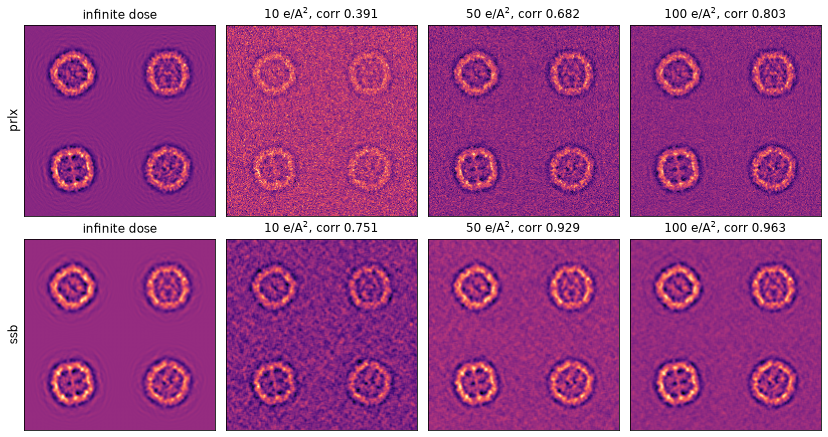

In [22]:
fig, axes = plt.subplots(2, len(doses) + 1, figsize=(2.9 * (len(doses) + 1), 6.2))
for row, name in enumerate(kernels):
    axes[row, 0].imshow(reference[name], cmap="magma")
    axes[row, 0].set_ylabel(name, fontsize=12)
    axes[row, 0].set_title("infinite dose")
    for col, dose in enumerate(doses, start=1):
        axes[row, col].imshow(results[(dose, name)], cmap="magma")
        axes[row, col].set_title(
            f"{dose:.0f} e/A$^2$, corr "
            f"{correlation(results[(dose, name)], reference[name]):.3f}"
        )
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()

## Summary

An event list is a `Vector` whose fixed grid is the scan and whose ragged rows are the detected
electrons. The time column of a raw stream is spent assigning each electron to a scan position;
what remains is a detector coordinate, optionally with a count if repeats within a position have
been collapsed. `vector_from_frames` does the same conversion when you already hold counted
frames.

`from_vector` takes that alongside `probe_positions` and any detector-space `Dataset2d`, and
reproduces the dense reconstruction to float precision. Whether it is faster depends on the
detected electrons against `num_bf * canvas_pixels / 7`, so both the dose and the upsampling
factor matter. For `icom` the riCOM collapse is cheap either way, and for `prlx` the saving is
memory rather than time.